In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
import copy


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment\without_electronic_peak')
import P_and_P_no_electronic_peak_func
importlib.reload(P_and_P_no_electronic_peak_func)
from P_and_P_no_electronic_peak_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [2]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Detailed acoustic mode study\NDd zone 3\0 to 1000 ps'
dir_name = r'2026-01-07_PaP_Pp20uW_ldap410nm_ldas660nm'

dir_save_treated_data = dir_root + '\\' + dir_name + '_treated'

if not(os.path.exists( dir_save_treated_data)) :
        os.mkdir( dir_save_treated_data)

Data_set = P_and_P_dataset(dir_root, dir_name)

### Make a mean on all traces data

In [3]:
Data_set.synchronize_data()

### Find the time delay of the excitation

In [4]:
#Data_set.find_delay_zero(n_start=0, n_stop=-1, force_n=-1)
Data_set.find_delay_zero(n_start=0, n_stop=-1, force_n=0)

0
-2.5897653390234576e-05
2.930556092189312e-05


### Find the average signal before excitation

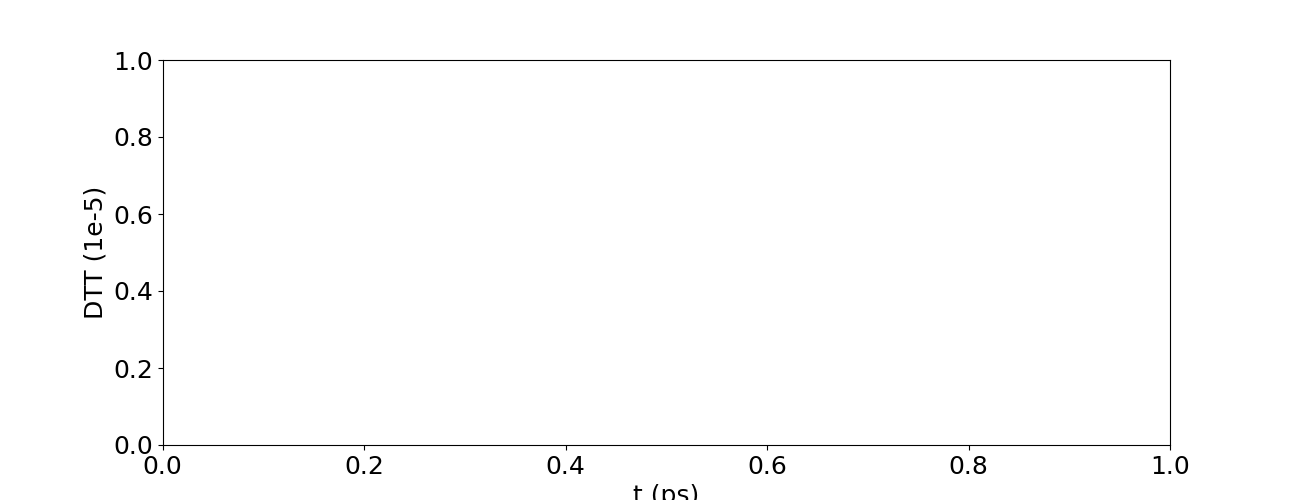

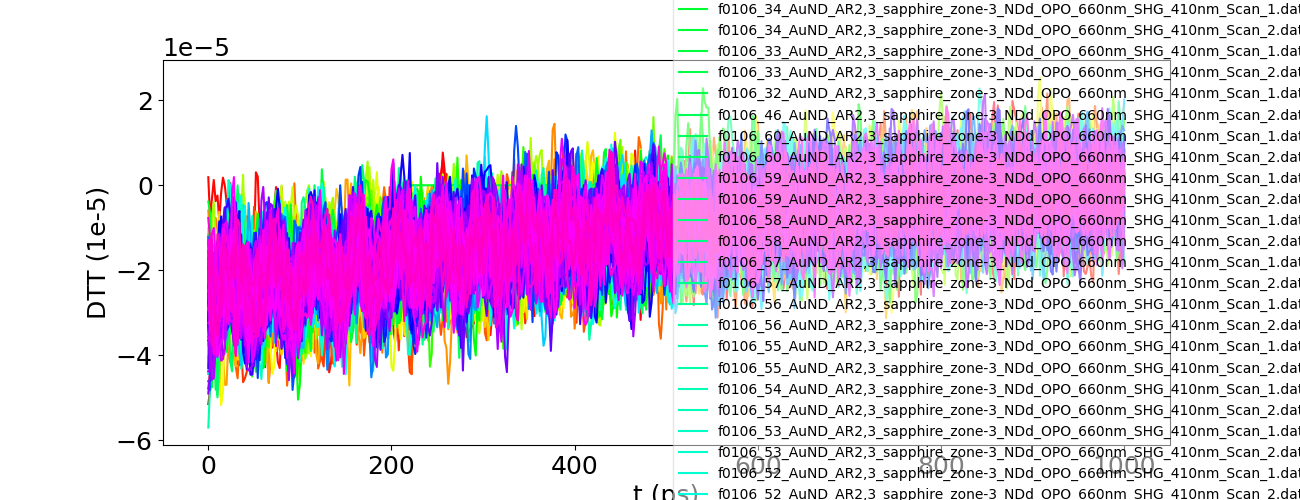

In [5]:
fig = Plot_all_traces_2(Data_set) 
fig = Plot_all_traces(Data_set) 

In [6]:
idx_start = 0 #index to start the mean
idx_end = Data_set.t0_index - 0 #index to end the mean

mean_start = 1.1e-5

Data_set.mean_start = mean_start


In [7]:
# print(mean_start)

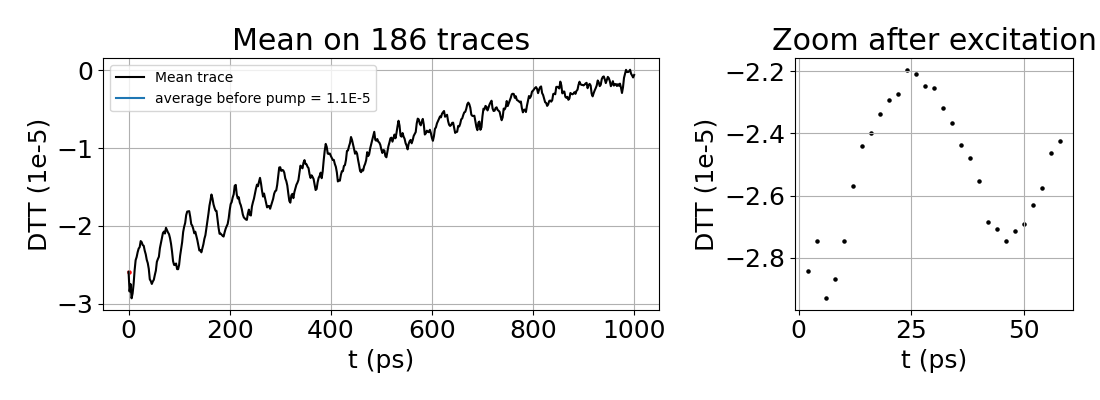

In [8]:
fig = Plot_mean_before_pulse(Data_set, idx_start, idx_end, mean_start) 


save_in_dir(fig, dir_save_treated_data, 'Mean_signal')

### Crop the delay to get the post-excitation signal

In [9]:
#Choose the starting index for the signal of interest
n_offset_start = 0

n_start = Data_set.t0_index + n_offset_start


Data_set.n_points_cropped = n_offset_start
Data_set.time_cropped = Data_set.t_step * Data_set.n_points_cropped
Data_set.crop_delay_and_remove_offset(n_start)

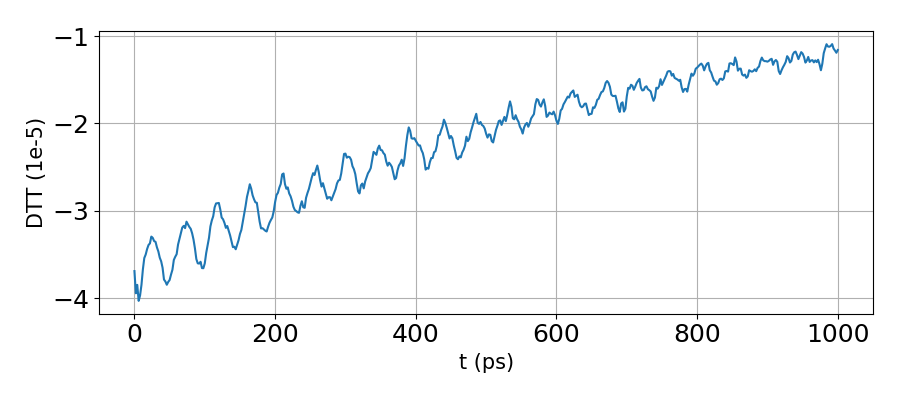

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
Plot_delay(Data_set, ax)
plt.tight_layout()

## Thermal_treatment

In [11]:
Trace = Data_set
height = 0.05e-5
threshold = 300e-7
ylim = 5e-7
Trace.tf_with_thermic = Trace.study_tf(Trace.DTT, Trace.delay, Trace.dt, height=height, threshold = threshold )

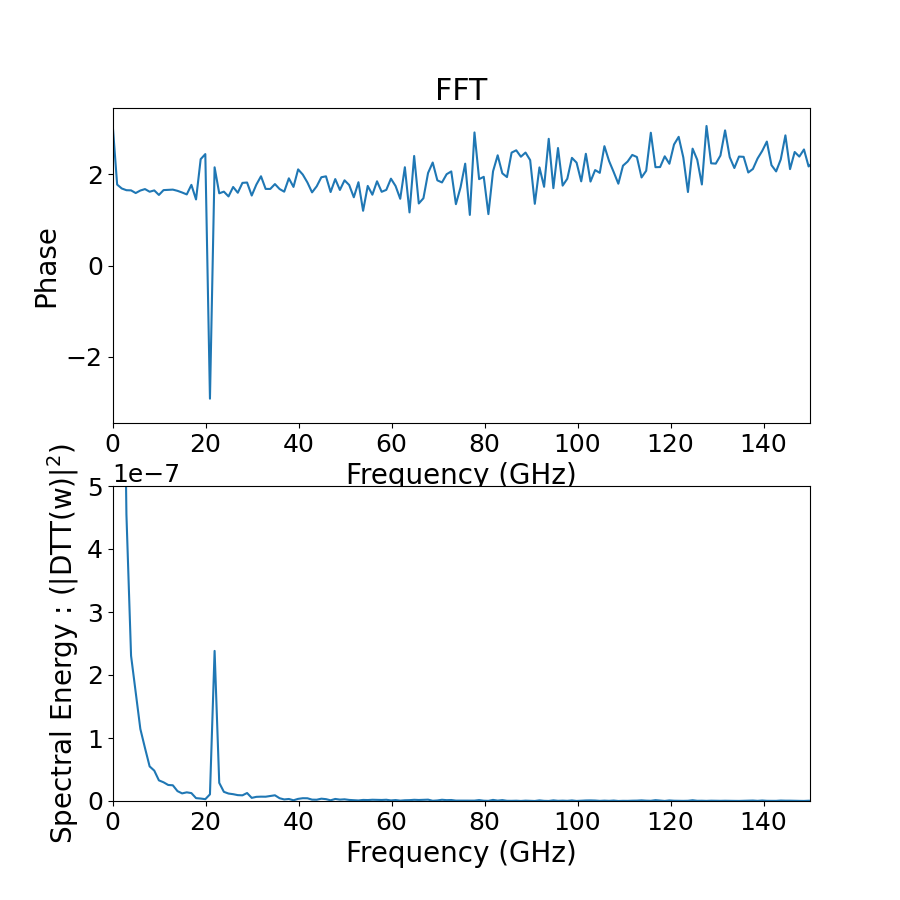

In [12]:
fig_raw_tf, ax_raw_tf = plt.subplots(nrows=2, figsize = (9, 9))

plot_tf_phase(Trace.tf_with_thermic, ax_raw_tf[0], ylim=ylim, xlim=(0, 150))
plot_tf_module(Trace.tf_with_thermic, ax_raw_tf[1], ylim=ylim, xlim=(0, 150))


#plt.tight_layout()
plt.show()

## Begin Thermal interpolation

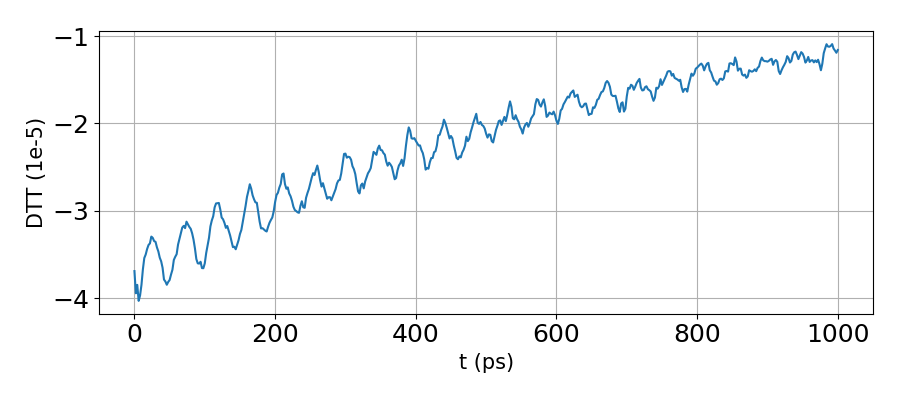

In [13]:
fig, ax = plt.subplots(figsize = (9,4))

Plot_delay(Trace, ax)
plt.tight_layout()

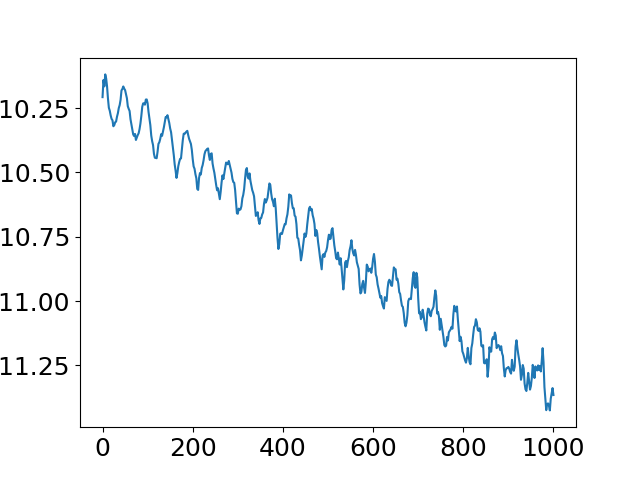

In [14]:
fig = plt.figure()

plt.plot(Trace.delay, np.log(-Trace.DTT))

### Create initial guesses and bounds

In [15]:
# Set the signal we're gonna fit
signe_pic = -1


#p0 = A1, tau1, A2, tau2, A3, tau3, A4, tau4. (times in ps)
p0 = signe_pic*1e-5, 300., signe_pic*0.5e-5, 100., signe_pic*1.e-5, 800., signe_pic*1e-5, 3200.
p0 = signe_pic*3e-5, 700., signe_pic*0.5e-5, 100., signe_pic*0.1e-5, 1000., signe_pic*0.1e-5, 2000.

if signe_pic == -1 :
    Bounds_low =  [-np.inf, 0, -np.inf, 15, -np.inf, 400, -np.inf, 1500]
    Bounds_high = [0,np.inf,0,np.inf,0,np.inf, 0, np.inf]

else :
    Bounds_low =  [0, 40, 0, 100, 0, 400, 0, 1500]
    Bounds_high = [np.inf,np.inf,np.inf,np.inf,np.inf,np.inf, np.inf, np.inf]

In [16]:
Trace.fit_thermal_signal(p0, Bounds_high, Bounds_low)

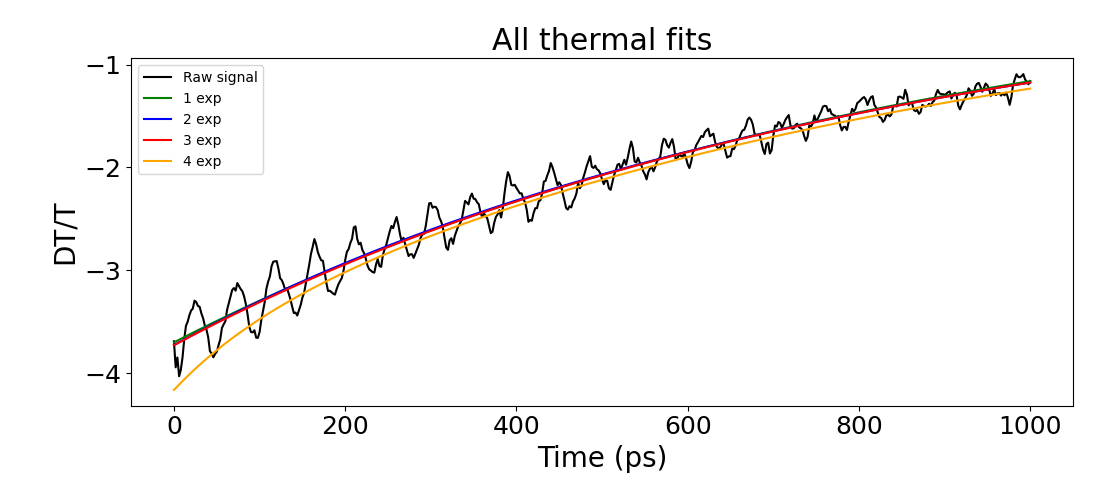

In [17]:
fig, ax = plt.subplots(figsize = (11,5))

Plot_multiple_thermal_fit(Trace,ax, n_min=1, n_max=4)
plt.tight_layout()
#save_in_dir(ftot, dir_save_treated_data, 'Thermal fits')

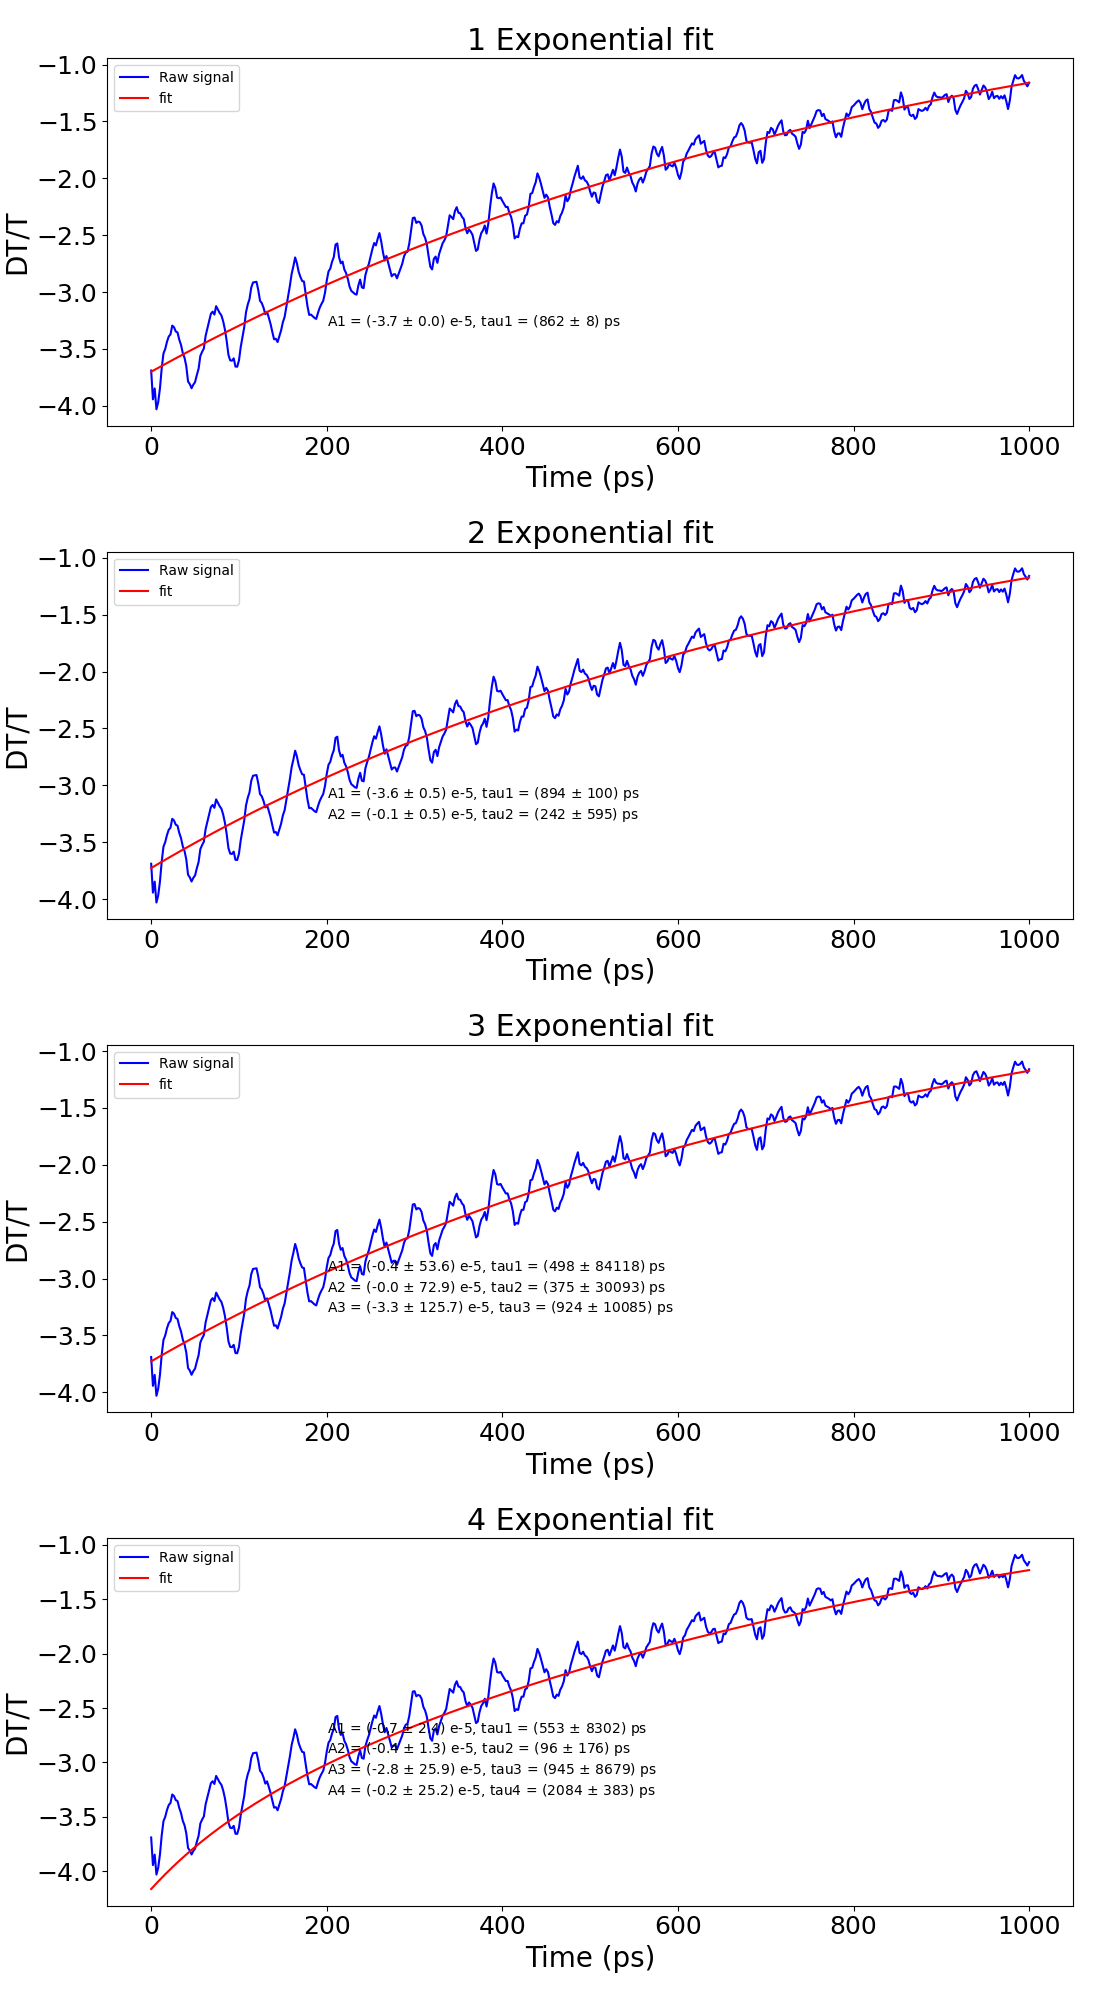

In [18]:
fig, ax = plt.subplots(nrows = 4,figsize = (11,20))

Plot_thermal_fit(Trace, ax[0], n_exp = 1)
Plot_thermal_fit(Trace, ax[1], n_exp = 2)
Plot_thermal_fit(Trace, ax[2], n_exp = 3)
Plot_thermal_fit(Trace, ax[3], n_exp = 4)
plt.tight_layout()
save_in_dir(fig, dir_save_treated_data, 'all_thermal_fits')



## Acoustic Treatment

### Get the data that we'll use for acoustic fitting

In [19]:
# Option 2 : we use the same data as for thermal fitting.
Trace_acoustic = copy.deepcopy(Trace)


In [20]:
n_exp =1
Trace_acoustic.remove_thermic_part(Trace, n_exp)

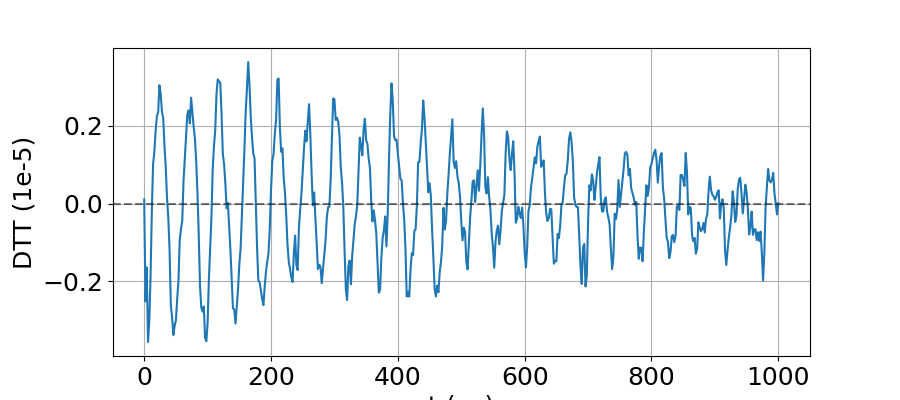

In [21]:
fig_acoustic_raw , ax_acoustic_raw = plt.subplots(figsize = (9,4))

ax_acoustic_raw = Plot_acoustic_raw(Trace_acoustic, ax_acoustic_raw)

plt.show()


save_in_dir(fig_acoustic_raw, dir_save_treated_data, 'Acoustic signal raw')

Make TF

In [22]:
height = 1e-7
threshold = 1e-7
ylim = 5e-7

Trace_acoustic.tf_acoustic = Trace_acoustic.study_tf(Trace_acoustic.DTT_acoustic, Trace_acoustic.delay, Trace_acoustic.dt, height=height, threshold = threshold )

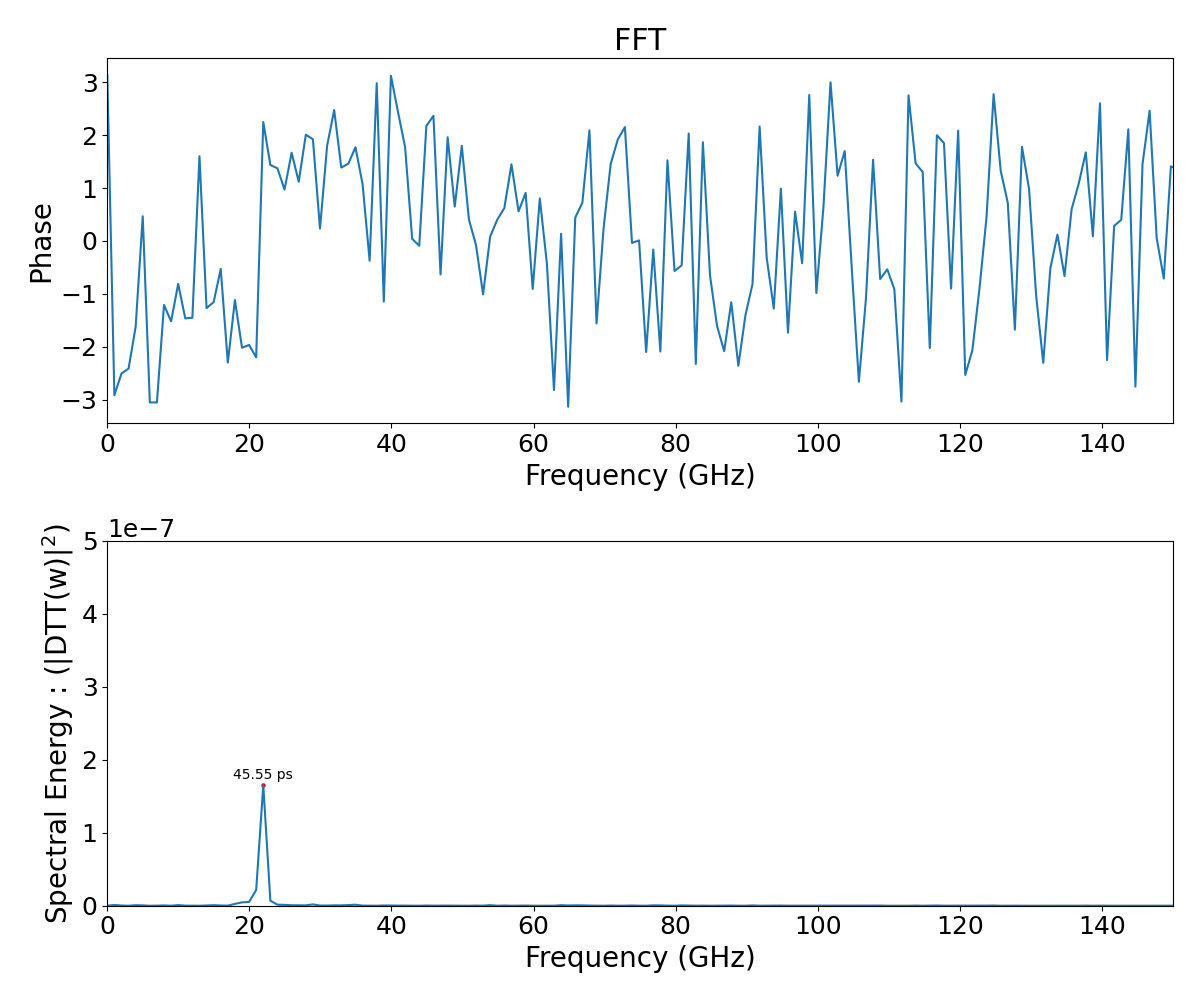

In [23]:
fig_raw_tf, ax_raw_tf = plt.subplots(nrows=2, figsize = (12, 10))

normalize_magnitude = False

plot_tf_phase(Trace_acoustic.tf_acoustic, ax_raw_tf[0], ylim=ylim, xlim=(0, 150))
plot_tf_module(Trace_acoustic.tf_acoustic, ax_raw_tf[1], ylim=ylim, xlim=(0, 150), normalized=normalize_magnitude)

if normalize_magnitude :
    ax_raw_tf[1].set_ylim((0, 1))
plt.tight_layout()
plt.show()

save_in_dir(fig_raw_tf, dir_save_treated_data, 'TF acoustic')

## Acoustic time interpolation

Make bounds and initial guess

In [24]:
#p0 = A1, tau1, T1, phi1, A2, tau2, T2, phi2, A3, tau3, T3, phi3, A4, tau4, T4, phi4
A1_0, tau1_0, T1_0, phi1_0 = 15e-5, 170, 1/(22.2)*1e3, (100)*np.pi/180
A2_0, tau2_0, T2_0, phi2_0 = 1e-5, 300,1/(22)*1e3, (-146)*np.pi/180
A3_0, tau3_0, T3_0, phi3_0 = 0.1e-5, 100, 31, -100*np.pi/180
A4_0, tau4_0, T4_0, phi4_0 = 0.5e-5, 200, 30, 0.5


p0 = A1_0, tau1_0, T1_0, phi1_0, A2_0, tau2_0, T2_0, phi2_0, A3_0, tau3_0, T3_0, phi3_0, A4_0, tau4_0, T4_0, phi4_0

Bounds_low = [ 0, 0, 0, -np.pi, 0, 0, 0, -np.pi, 0, 0, 0, -np.pi, 0, 0, 0, -np.pi]
Bounds_high= [np.inf,np.inf,np.inf,np.pi,np.inf, np.inf, np.inf, np.pi,np.inf,np.inf,np.inf,np.pi,np.inf, np.inf, np.inf, np.pi]

In [25]:
Trace_acoustic.fit_acoustic(p0,Bounds_high, Bounds_low)

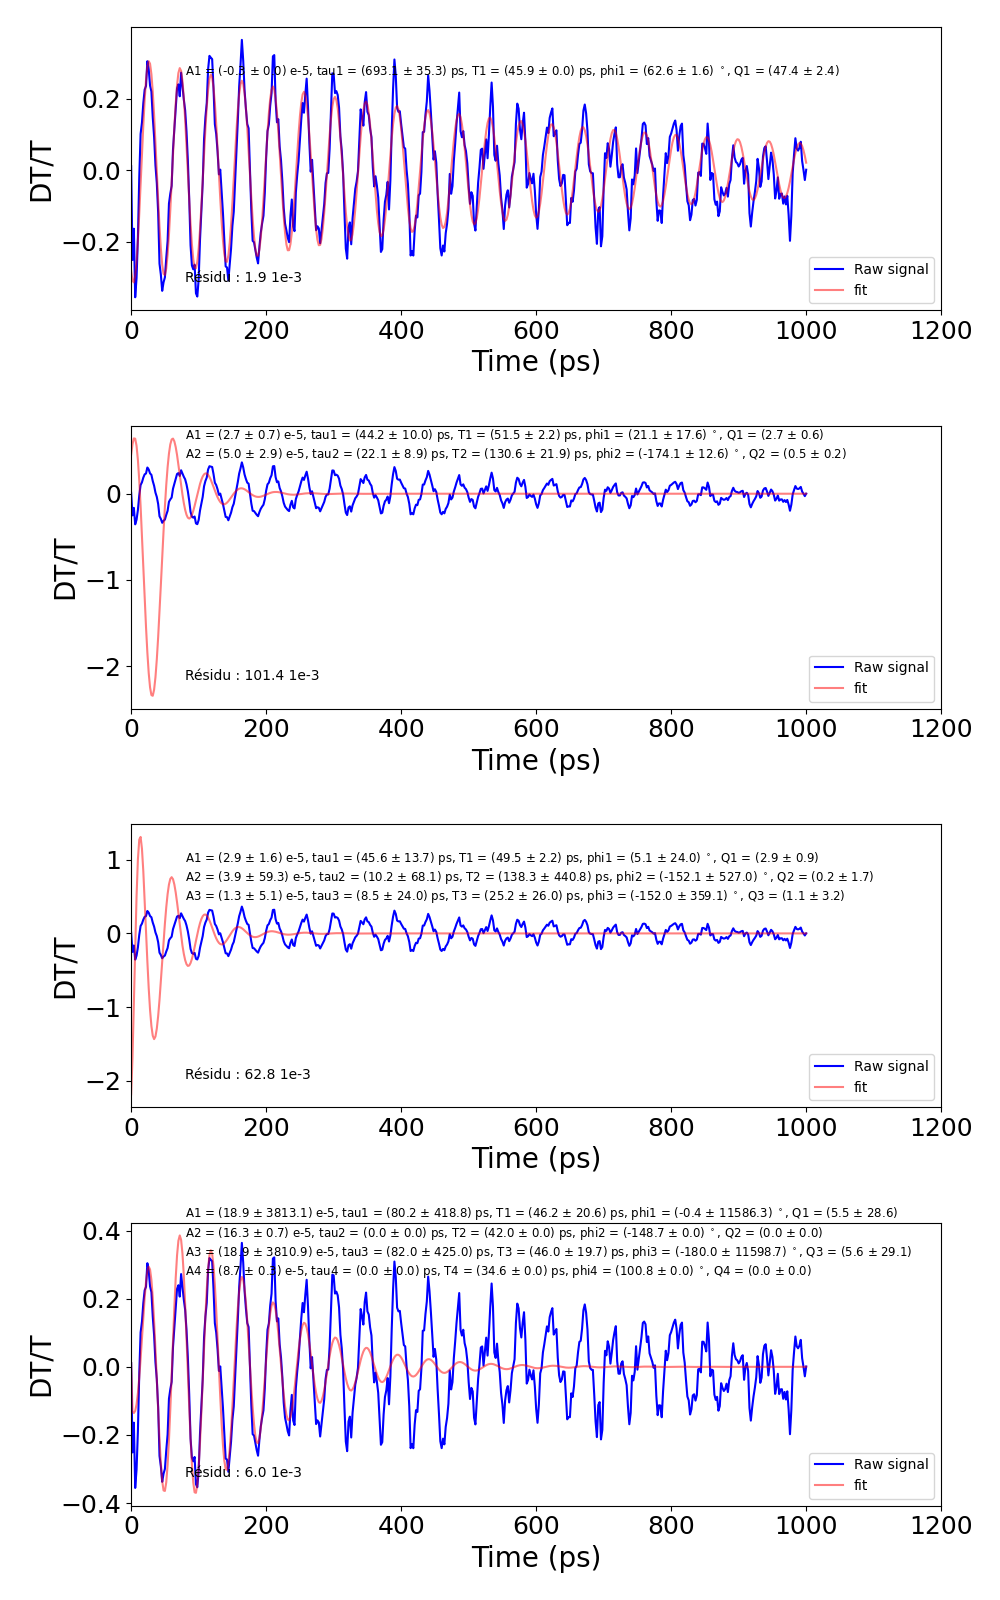

In [26]:
tmax=1200

fig_fit_acoustic, ax_fit_acoustic = plt.subplots(nrows = 4, figsize=(10,16))

Plot_acoustic_fit(Trace_acoustic, ax_fit_acoustic[0], n_modes=1, tmax=tmax )
Plot_acoustic_fit(Trace_acoustic, ax_fit_acoustic[1], n_modes=2, tmax=tmax )
Plot_acoustic_fit(Trace_acoustic, ax_fit_acoustic[2], n_modes=3, tmax=tmax )
Plot_acoustic_fit(Trace_acoustic, ax_fit_acoustic[3], n_modes=4, tmax=tmax )
plt.tight_layout()
plt.show()

save_in_dir(fig_fit_acoustic, dir_save_treated_data, 'Fit acoustic - all modes')

## Acoustic study synthesis

In [27]:
n_modes_acoustic = 1
n_exp_thermic = n_exp

Trace_acoustic.n_modes_acoustic = n_modes_acoustic
Trace_acoustic.n_exp_thermic = n_exp_thermic
tmax = tmax

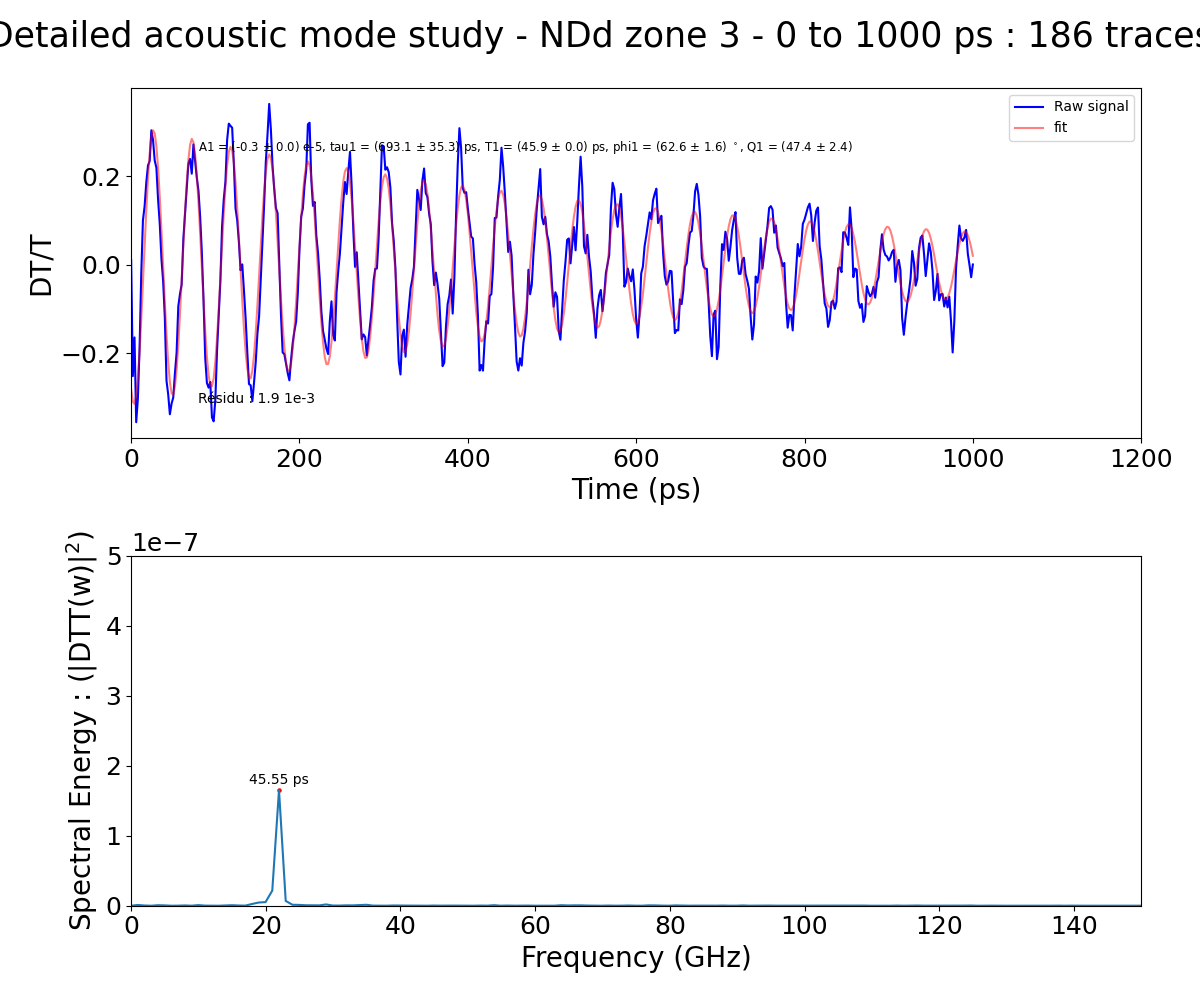

In [28]:
fig_synthese, ax = figs, ax = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 10),
)

#Plot_acoustic_raw(Trace_acoustic, ax[0])
Plot_acoustic_fit(Trace_acoustic, ax[0], n_modes=n_modes_acoustic, tmax=tmax )
plot_tf_module(Trace_acoustic.tf_acoustic, ax[1], ylim=ylim, xlim=(0, 150))

list_info = Trace_acoustic.dir_root.split('\\')
plt.suptitle('{} - {} - {} : {} traces'.format(list_info[-3], list_info[-2], list_info[-1], Trace_acoustic.n_traces), fontsize=25)
plt.tight_layout()


save_in_dir(fig_synthese, dir_save_treated_data, 'Synthèse fit acoustic')

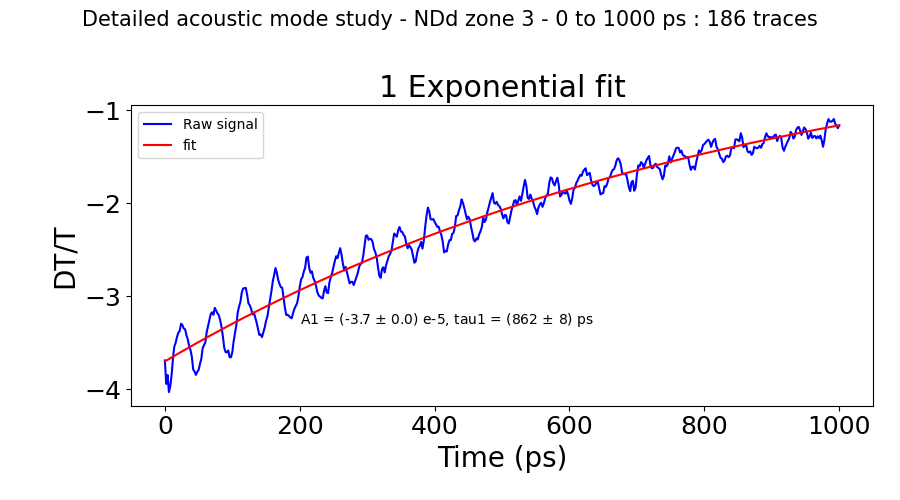

In [29]:
fig_synthese_thermal, ax_synth_thermal = plt.subplots(figsize=(9,5))

Plot_thermal_fit(Trace_acoustic, ax_synth_thermal, n_exp=n_exp_thermic )
list_info = Trace_acoustic.dir_root.split('\\')
plt.suptitle('{} - {} - {} : {} traces'.format(list_info[-3], list_info[-2], list_info[-1], Trace_acoustic.n_traces), fontsize=15)

plt.tight_layout()

save_in_dir(fig_synthese_thermal, dir_save_treated_data, 'Synthèse fit thermal')

In [30]:
dir_to_save = Trace_acoustic.dir_root + '\\' + Trace_acoustic.dir_name + r'_treated'
filename='Trace'
filename_acoustic = filename + '_acoustic_fitted'

save_PaP_dataset(Trace_acoustic, dir_to_save, filename_acoustic)

save_signal_and_fits_curves(Trace_acoustic)
save_fits_coeffs_thermic(Trace_acoustic)
save_fits_coeffs_acoustic(Trace_acoustic)